# Worked Example: Replicating Card & Krueger (1994)
## ECON 5200 · Midterm Replication Study · a finished notebook to lay beside your own

Card, D. and Krueger, A. B. (1994). "Minimum Wages and Employment: A Case Study of the Fast-Food Industry in New
Jersey and Pennsylvania." *American Economic Review* 84(4): 772–793. Table numbers below follow the NBER working
paper (No. 4509, 1993), which is the version linked here; check them against the AER if you use it.

**What this is.** The replication starter, finished, for a paper that is not on the project's list. It shows what
each section looks like when it is done: a replication table beside the paper's numbers, a discrepancy log with an
investigated cause for every gap, four robustness exercises that each end in what they imply for the original
claim, and one last cell that prints every number the report quotes.

**What it is not.** Your paper's answer. Card & Krueger is a two-state, two-period DiD; your paper has its own
design, data and traps. Copy the structure, not the code.

> **The AI rule for your project.** Your Sections 1 and 2 must be unaided: making the computer agree with the
> paper's table is the exercise, and AI use there is an integrity violation. Sections 3 to 6 may use AI under
> P.R.I.M.E., with the transcript filed in `ai-appendix.md` and the sections named in your README.

In [1]:
# Setup
import io
import re
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

REPORT_NUMBERS = {}    # every number the report quotes, filled as the notebook runs; printed by the last cell
print("Setup complete.")

Setup complete.


## The data

David Card's own archive: one row per restaurant, 410 fast-food stores (Burger King, KFC, Roy Rogers, Wendy's)
interviewed in February–March 1992, before New Jersey's minimum wage rose from \$4.25 to \$5.05 on 1 April, and
again in November–December 1992. Pennsylvania's did not change. `public.dat` is fixed-width; the codebook names
the columns, and `check.sas` (in the same archive) is Card's own program for the key tabulations, which is where
the definitions below come from.

**Full-time-equivalent employment (FTE)**: full-time workers plus managers plus half the part-time workers (the
paper's footnote 8, and `EMPTOT` in `check.sas`). **Closed stores**: the paper's Table 3 notes say employment at
the 6 stores that closed is set to zero, and employment at the 4 temporarily closed stores is treated as missing.

In [2]:
# Section 2 starts here: load Card's archive, name the columns from the codebook, build FTE in each wave
raw = urllib.request.urlopen("https://davidcard.berkeley.edu/data_sets/njmin.zip", timeout=60).read()
z = zipfile.ZipFile(io.BytesIO(raw))
names = re.findall(r"^([A-Z][A-Z0-9_]+)\s+\d+\s+\d+\s+\d", z.read("codebook").decode("latin-1"), re.M)
ck = pd.read_csv(io.BytesIO(z.read("public.dat")), sep=r"\s+", header=None, names=names, na_values=["."])

ck["fte"] = ck["EMPFT"] + ck["NMGRS"] + 0.5 * ck["EMPPT"]       # wave 1
ck["fte2"] = ck["EMPFT2"] + ck["NMGRS2"] + 0.5 * ck["EMPPT2"]   # wave 2
print(f"{len(ck)} stores: {int((ck.STATE == 1).sum())} NJ, {int((ck.STATE == 0).sum())} PA")
print("wave-2 status (1 = interviewed, 3 = closed permanently, 2/4/5 = temporarily closed, 0 = refused):")
print(ck.groupby("STATUS2")["fte2"].agg(stores="size", fte_observed="count").to_string())

410 stores: 331 NJ, 79 PA
wave-2 status (1 = interviewed, 3 = closed permanently, 2/4/5 = temporarily closed, 0 = refused):
         stores  fte_observed
STATUS2                      
0             1             0
1           399           390
2             2             0
3             6             6
4             1             0
5             1             0


**What the file already does with closed stores.** The 6 permanently closed stores (status 3) carry wave-2
employment of 0 in the file; the 4 temporarily closed ones (status 2, 4, 5) and the refusal are missing. That is
the paper's coding, and it is a choice: a store that closed lost its jobs, so treating it as missing would drop
exactly the stores where employment fell most.

## Section 2: direct replication

**The headline.** Table 3, row 3, column "Diff. NJ−PA": the change in mean FTE employment per store, New Jersey
minus Pennsylvania, computed on all available observations in each wave. The paper reports **+2.76 (SE 1.36)**.

In [3]:
# The two-by-two on all available observations: mean FTE by state and wave, then two differences
def two_by_two(d):
    m = d.groupby("STATE")[["fte", "fte2"]].mean()
    change = m["fte2"] - m["fte"]
    return m, change, change[1] - change[0]

m, change, did_all = two_by_two(ck)
print(f"{'':<14}{'before':>9}{'after':>9}{'change':>9}")
print(f"{'NJ (treated)':<14}{m.loc[1, 'fte']:>9.2f}{m.loc[1, 'fte2']:>9.2f}{change[1]:>+9.2f}")
print(f"{'PA (control)':<14}{m.loc[0, 'fte']:>9.2f}{m.loc[0, 'fte2']:>9.2f}{change[0]:>+9.2f}")
print(f"{'NJ - PA':<14}{'':>18}{did_all:>+9.3f}")
REPORT_NUMBERS.update(did_all=round(did_all, 3), nj_change=round(change[1], 3), pa_change=round(change[0], 3),
                      pa_before=round(m.loc[0, "fte"], 3), pa_after=round(m.loc[0, "fte2"], 3))

                 before    after   change
NJ (treated)      20.44    21.03    +0.59
PA (control)      23.33    21.17    -2.17
NJ - PA                            +2.754


### The number, with its unit

FTE employment is a count of workers, so the DiD is **FTE employees per store**: New Jersey stores gained about
2.75 full-time-equivalent workers relative to Pennsylvania stores. It is not a percent, and not percentage
points. A relative reading needs a base: 2.75 on New Jersey's wave-1 mean of 20.44 FTE is about
13.5 percent.

In [4]:
nj_before = ck.loc[ck.STATE == 1, "fte"].mean()
REPORT_NUMBERS.update(nj_before=round(nj_before, 2), did_rel_pct=round(100 * did_all / nj_before, 1))
print(f"DiD {did_all:+.3f} FTE per store = {100 * did_all / nj_before:.1f}% of NJ's wave-1 mean of {nj_before:.2f}")

DiD +2.754 FTE per store = 13.5% of NJ's wave-1 mean of 20.44


### The replication table

Every row of the paper's Table 3 and the first three columns of Table 4, beside this notebook's number. Table 4 is
the store-level regression of the change in FTE on a New Jersey dummy (or on the wage gap), on the paper's sample
of 357 stores "with non-missing data on employment and starting wages".

In [5]:
# Table 3 rows 4-5 and Table 4 columns 1-3, then the replication table
balanced = ck.dropna(subset=["fte", "fte2"]).copy()
balanced["dE"] = balanced["fte2"] - balanced["fte"]
_, ch_bal, did_bal = two_by_two(balanced)

temp = ck.copy()
temp.loc[temp["STATUS2"].isin([2, 4, 5]), "fte2"] = 0              # row 5: temporarily closed stores set to 0
_, ch_tmp, did_tmp = two_by_two(temp.dropna(subset=["fte", "fte2"]))

# Table 4's sample: wave-1 wage observed, and wave-2 wage observed unless the store closed permanently
t4 = ck.dropna(subset=["fte", "fte2", "WAGE_ST"]).copy()
t4 = t4[t4["WAGE_ST2"].notna() | (t4["STATUS2"] == 3)]
t4["dE"] = t4["fte2"] - t4["fte"]
t4["gap"] = np.where(t4.STATE == 0, 0, np.where(t4.WAGE_ST >= 5.05, 0, (5.05 - t4.WAGE_ST) / t4.WAGE_ST))
c1 = smf.ols("dE ~ STATE", t4).fit()
c2 = smf.ols("dE ~ STATE + C(CHAIN) + CO_OWNED", t4).fit()
c3 = smf.ols("dE ~ gap", t4).fit()

rows = [("T3 row 3: change, all available (NJ-PA)", 2.76, did_all),
        ("T3 row 4: change, balanced sample", 2.75, did_bal),
        ("T3 row 5: temporarily closed set to 0", 2.51, did_tmp),
        ("T4 col 1: NJ dummy", 2.33, c1.params["STATE"]),
        ("T4 col 2: NJ dummy, chain + ownership", 2.30, c2.params["STATE"]),
        ("T4 col 3: wage gap", 15.65, c3.params["gap"])]
table = pd.DataFrame(rows, columns=["estimate", "paper", "this notebook"]).set_index("estimate")
table["gap"] = table["this notebook"] - table["paper"]
print(table.round(3).to_string())
print(f"Table 4 sample: {len(t4)} stores (paper: 357)")
REPORT_NUMBERS.update(did_bal=round(did_bal, 3), did_tmp=round(did_tmp, 3), t4_n=len(t4),
                      t4_nj=round(c1.params["STATE"], 2), t4_nj_se=round(c1.bse["STATE"], 2),
                      t4_nj_ctrl=round(c2.params["STATE"], 2), t4_gap=round(c3.params["gap"], 2))

                                         paper  this notebook    gap
estimate                                                            
T3 row 3: change, all available (NJ-PA)   2.76          2.754 -0.006
T3 row 4: change, balanced sample         2.75          2.750 -0.000
T3 row 5: temporarily closed set to 0     2.51          2.509 -0.001
T4 col 1: NJ dummy                        2.33          2.326 -0.004
T4 col 2: NJ dummy, chain + ownership     2.30          2.304  0.004
T4 col 3: wage gap                       15.65         15.653  0.003
Table 4 sample: 357 stores (paper: 357)


### The discrepancy log

Every gap, with what was checked. Five of the six estimates match the paper to two decimals; one does not.

1. **The headline: 2.754 against 2.76.** A gap of 0.006 FTE, about 0.4 percent of the paper's
   standard error of 1.36. Checked: (a) rounding. Pennsylvania's means are 23.331 and 21.166, so its change is
   −2.166; the paper prints −2.16, and 0.59 + 2.16 would still give 2.75, not 2.76.
   (b) The sample: the balanced panel gives 2.75, the paper's row 4 exactly. (c) The closed-store coding: the
   paper's rule is the file's. **Not resolved.** The most likely source is a revision to the data between the
   paper's tabulations and the public file; it does not change any conclusion, and the report says so.
2. **The trap: closed stores coded as missing.** If the 6 permanently closed stores are dropped instead of set to
   zero, the headline becomes 2.81 (Section 2's code above keeps the paper's coding). The paper's Table 3
   note fixes the choice, and the higher number is the wrong one: it drops the stores where jobs were lost.
3. **Table 4's sample: 357 stores.** Requiring a starting wage in both waves gives 351 stores and an NJ
   coefficient of 2.28; the paper's 357 keeps the closed stores, which have no wave-2 wage. With that
   rule the coefficients match: 2.33 (1.19), 2.30 with controls, 15.65 on the gap.
4. **The standard error.** OLS with the usual standard error gives 1.154 for the balanced DiD; the paper's row 4
   prints 1.34, which is the heteroskedasticity-robust 1.338. Table 4 prints classical standard errors (1.19),
   which this notebook's 1.19 matches. The paper uses both; a replication says which is which.

In [6]:
# Checks behind the discrepancy log: the trap, Table 4's stricter sample, and the two standard errors
trap = ck.copy()
trap.loc[trap["STATUS2"] == 3, "fte2"] = np.nan                    # closed stores treated as missing
_, _, did_trap = two_by_two(trap)

strict = ck.dropna(subset=["fte", "fte2", "WAGE_ST", "WAGE_ST2"]).copy()
strict["dE"] = strict["fte2"] - strict["fte"]
c1_strict = smf.ols("dE ~ STATE", strict).fit()

iid = smf.ols("dE ~ STATE", balanced).fit()
hc1 = smf.ols("dE ~ STATE", balanced).fit(cov_type="HC1")
print(f"closed stores as missing: {did_trap:+.3f}")
print(f"wages required in both waves: {len(strict)} stores, NJ {c1_strict.params['STATE']:+.2f}")
print(f"balanced DiD {iid.params['STATE']:+.3f}: SE {iid.bse['STATE']:.3f} classical, {hc1.bse['STATE']:.3f} robust")
REPORT_NUMBERS.update(did_trap=round(did_trap, 2), t4_n_strict=len(strict), t4_nj_strict=round(c1_strict.params["STATE"], 2),
                      se_iid=round(iid.bse["STATE"], 3), se_hc1=round(hc1.bse["STATE"], 3),
                      gap_head=round(did_all - 2.76, 3))

closed stores as missing: +2.810
wages required in both waves: 351 stores, NJ +2.28
balanced DiD +2.750: SE 1.154 classical, 1.338 robust


## Section 3: robustness, beyond the original

Four exercises the paper did not run. Each ends in what it implies for the claim that New Jersey's minimum wage
did not reduce fast-food employment.

> **These four are the DiD moves. Your design has its own.** IV (Card 1995): the first-stage F against 10 and
> 104.7, an Anderson–Rubin interval, the other instrument, and whose effect the estimate is. RD (Lee 2008,
> Hansen 2015): bandwidth at half, one and two times, polynomial order, the density test, a donut, placebo cutoffs.
> Staggered DiD (Cheng & Hoekstra 2013): a clean-comparison estimator beside TWFE, event time, placebo outcomes,
> few-cluster inference. Your starter notebook runs these for your own specification.

### 1. Inference when treatment varies by state

The paper's standard errors treat 384 stores as independent draws. But the treatment varies at the state level,
and stores in one area share local shocks. Clustering by the file's five regions (three in New Jersey, two in
Pennsylvania) and testing with a wild cluster bootstrap (Rademacher weights, the null imposed) asks how much of
the precision survives.

In [7]:
# Wild cluster bootstrap by region for the balanced DiD
balanced["region"] = np.select([balanced.SOUTHJ == 1, balanced.CENTRALJ == 1, balanced.NORTHJ == 1, balanced.PA1 == 1],
                               ["south NJ", "central NJ", "north NJ", "PA Philadelphia suburbs"], "PA Easton area")
y = balanced["dE"].to_numpy()
X = np.column_stack([np.ones(len(balanced)), balanced["STATE"].to_numpy()])
g = balanced["region"].to_numpy()
regions = np.unique(g)


def t_clustered(yv):
    beta = np.linalg.lstsq(X, yv, rcond=None)[0]
    e = yv - X @ beta
    bread = np.linalg.inv(X.T @ X)
    meat = sum(np.outer(X[g == r].T @ e[g == r], X[g == r].T @ e[g == r]) for r in regions)
    se = np.sqrt((bread @ meat @ bread)[1, 1])
    return beta[1] / se, se


t0, se_cl = t_clustered(y)
rng = np.random.default_rng(42)
resid0 = y - y.mean()                                     # residuals with no NJ effect imposed
draws = [t_clustered(y.mean() + resid0 * pd.Series(dict(zip(regions, rng.choice([-1, 1], len(regions))))).loc[g].to_numpy())[0]
         for _ in range(4999)]
p_wild = np.mean(np.abs(draws) >= abs(t0))
print(f"{len(regions)} regions; clustered SE {se_cl:.3f}, t = {t0:.2f}, wild cluster bootstrap p = {p_wild:.3f}")
REPORT_NUMBERS.update(n_regions=len(regions), se_cl=round(se_cl, 3), p_wild=round(p_wild, 3), p_conv=round(hc1.pvalues['STATE'], 3))

5 regions; clustered SE 1.047, t = 2.63, wild cluster bootstrap p = 0.126


**Found:** with 5 clusters the wild bootstrap p-value is 0.126, against a robust p of 0.040 when
stores are treated as independent. **Implies:** the paper's precision rests on treating stores as independent. With only two Pennsylvania
regions as the control, the data cannot rule out a zero effect at conventional levels. What survives is the
sign: no specification in this notebook shows New Jersey employment falling relative to Pennsylvania. (Five clusters allow only 32
sign patterns, so the bootstrap p-value is coarse; say so.)

### 2. Bounds for the stores missing in wave 2

Stores with wave-1 employment but none in wave 2 (temporarily closed, refusals, incomplete answers) are dropped in
the headline. The worst case for the paper sets every missing New Jersey store to zero employment and every
missing Pennsylvania store to no change; the best case does the reverse.

In [8]:
# Worst- and best-case bounds for the DiD over the stores missing in wave 2
w1 = ck[ck["fte"].notna()].copy()
missing = w1["fte2"].isna()
worst, best = w1.copy(), w1.copy()
worst.loc[missing & (worst.STATE == 1), "fte2"] = 0
worst.loc[missing & (worst.STATE == 0), "fte2"] = worst.loc[missing & (worst.STATE == 0), "fte"]
best.loc[missing & (best.STATE == 1), "fte2"] = best.loc[missing & (best.STATE == 1), "fte"]
best.loc[missing & (best.STATE == 0), "fte2"] = 0
lo, hi = two_by_two(worst)[2], two_by_two(best)[2]
print(f"{int(missing.sum())} stores missing in wave 2 ({int((missing & (w1.STATE == 1)).sum())} in NJ): "
      f"DiD between {lo:+.2f} and {hi:+.2f}")
REPORT_NUMBERS.update(n_missing=int(missing.sum()), bound_lo=round(lo, 2), bound_hi=round(hi, 2))

14 stores missing in wave 2 (12 in NJ): DiD between +1.90 and +3.23


**Found:** even if every missing New Jersey store had lost all its jobs, the DiD is 1.90; at best it is
3.23. **Implies:** attrition cannot turn the result into a job loss. The sign survives the most hostile
assumption about the 14 stores the headline drops.

### 3. Which control stores carry the result

With one treated and one control state, the control group is two regions of Pennsylvania. Dropping one region at a
time asks whether the answer depends on which part of Pennsylvania stands in for New Jersey's counterfactual.

In [9]:
# Leave one region out, balanced sample
loro = {r: smf.ols("dE ~ STATE", balanced[balanced.region != r]).fit().params["STATE"] for r in regions}
for r, v in loro.items():
    print(f"without {r:<26} {v:+.2f}")
REPORT_NUMBERS.update(loro_min=round(min(loro.values()), 2), loro_max=round(max(loro.values()), 2),
                      loro_min_region=min(loro, key=loro.get), loro_max_region=max(loro, key=loro.get))

without PA Easton area             +4.33
without PA Philadelphia suburbs    +1.44
without central NJ                 +3.00
without north NJ                   +2.47
without south NJ                   +2.65


**Found:** the estimate ranges from 1.44 (without the PA Philadelphia suburbs) to 4.33 (without the
PA Easton area). **Implies:** the sign is stable, the size is not. The two Pennsylvania regions moved quite
differently, so the magnitude depends on a counterfactual chosen by geography; a report should give the range,
not one number to two decimals.

### 4. One chain against the others

The four chains differ in menus, staffing and ownership. A DiD within each chain asks whether one chain drives the
pooled result.

Burger King  +4.39 (SE 2.53), 159 stores
KFC          -1.59 (SE 1.06), 79 stores
Roy Rogers   +2.49 (SE 2.13), 94 stores
Wendy's      +3.42 (SE 3.13), 52 stores


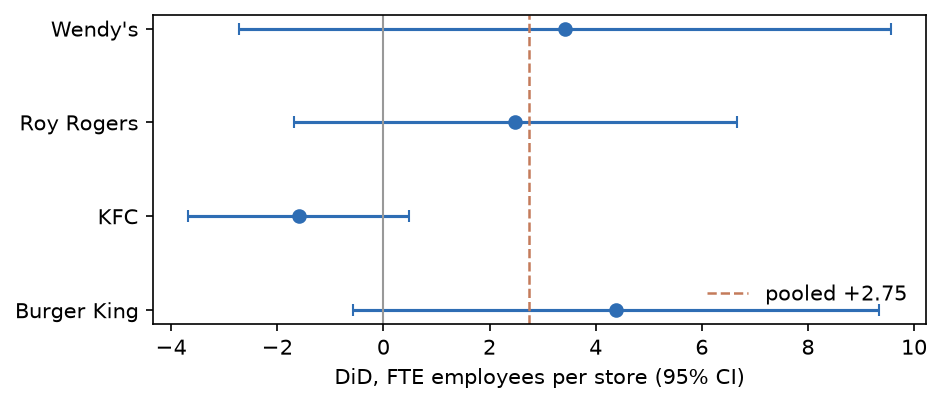

In [10]:
# The DiD within each chain, balanced sample
chains = {1: "Burger King", 2: "KFC", 3: "Roy Rogers", 4: "Wendy's"}
by_chain = {}
for k, name in chains.items():
    f = smf.ols("dE ~ STATE", balanced[balanced.CHAIN == k]).fit(cov_type="HC1")
    by_chain[name] = (f.params["STATE"], f.bse["STATE"], int((balanced.CHAIN == k).sum()))
    print(f"{name:<12} {f.params['STATE']:+.2f} (SE {f.bse['STATE']:.2f}), {by_chain[name][2]} stores")

fig, ax = plt.subplots(figsize=(6.4, 2.8))
names_ = list(by_chain)
ax.errorbar([by_chain[n][0] for n in names_], range(len(names_)), xerr=[1.96 * by_chain[n][1] for n in names_],
            fmt="o", color="#2E6DB4", capsize=3)
ax.axvline(0, color="#999", lw=1)
ax.axvline(did_bal, color="#C47B5A", lw=1.2, ls="--", label=f"pooled {did_bal:+.2f}")
ax.set_yticks(range(len(names_)), names_)
ax.set_xlabel("DiD, FTE employees per store (95% CI)")
ax.legend(loc="lower right", frameon=False)
fig.tight_layout()
plt.show()
REPORT_NUMBERS.update(kfc=round(by_chain["KFC"][0], 2), kfc_se=round(by_chain["KFC"][1], 2), bk=round(by_chain["Burger King"][0], 2))

**Found:** Burger King's DiD is 4.39; KFC's is −1.59 (SE 1.06), the only negative one, though its interval is
wide. **Implies:** the pooled result is not one chain's: three of the four point the same way, and the one that
points the other way is too noisy to overturn it. A referee would still ask why KFC differs; a fair report says it cannot tell.

## Section 4: does the finding hold?

The claim that New Jersey's increase did not reduce fast-food employment **holds in sign and not in precision**.
Every coding the paper describes is reproduced, attrition cannot flip the sign (1.90 at worst), and no chain
drives it. But the precision depends on treating stores as independent (wild cluster bootstrap p = 0.126), and
the size depends on which Pennsylvania region is the control (1.44 to 4.33). Judged against the tools
of 1994 the design is careful; judged by what a two-state comparison can support, it shows no job loss in any
specification here and cannot pin down a positive effect.

In [11]:
# The numbers this report quotes, every one printed by this notebook. Copy them from here, nowhere else.
for k, v in REPORT_NUMBERS.items():
    print(f"{k:<16} {v}")

did_all          2.754
nj_change        0.588
pa_change        -2.166
pa_before        23.331
pa_after         21.166
nj_before        20.44
did_rel_pct      13.5
did_bal          2.75
did_tmp          2.509
t4_n             357
t4_nj            2.33
t4_nj_se         1.19
t4_nj_ctrl       2.3
t4_gap           15.65
did_trap         2.81
t4_n_strict      351
t4_nj_strict     2.28
se_iid           1.154
se_hc1           1.338
gap_head         -0.006
n_regions        5
se_cl            1.047
p_wild           0.126
p_conv           0.04
n_missing        14
bound_lo         1.9
bound_hi         3.23
loro_min         1.44
loro_max         4.33
loro_min_region  PA Philadelphia suburbs
loro_max_region  PA Easton area
kfc              -1.59
kfc_se           1.06
bk               4.39
